In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!ls "/content/drive/MyDrive"

 031aa2d85132ddc370fd9f35736da5ca.mp4
 1633754756611.png
 1633755003465.jpg
'annotated-pc1-jOSE%20ramos-1 (1).pdf'
'Audio de Fer'
'Audio de Fer (1)'
'Audio de Fer (2)'
'Audio de Fer (3)'
'Audio de Fer (4)'
'Audio de Fer (5)'
'Carlos negro'
'Caso etica.docx'
'Colab Notebooks'
 com.feralinteractive.gridautosport_edition_android
 cronica.gdoc
'Cuestionario Diagnóstico de la Cultura Organizacional - Kim S. Cameron y Robert Quinn_10062971.docx'
'Cuestionario Diagnóstico de la Cultura Organizacional - Kim S. Cameron y Robert Quinn_10062971.pdf'
 dni.gdoc
 DOC-20240305-WA0011.pdf
'Documento de F.'
'Documento sin título (10).gdoc'
'Documento sin título (11).gdoc'
'Documento sin título (12).gdoc'
'Documento sin título (13).gdoc'
'Documento sin título (14).gdoc'
'Documento sin título (15).gdoc'
'Documento sin título (16).gdoc'
'Documento sin título (17).gdoc'
'Documento sin título (18).gdoc'
'Documento sin título (19).gdoc'
'Documento sin título (1).gdoc'
'Documento sin título (1).

In [ ]:
!cp "/content/drive/MyDrive/garbage-dataset.zip" .

In [ ]:
!ls -lh

total 745M
drwx------ 5 root root 4.0K Dec  3 13:02 drive
drwxr-xr-x 3 root root 4.0K Dec  3 13:03 garbage
-rw------- 1 root root 745M Dec  3 13:20 garbage-dataset.zip
drwxr-xr-x 1 root root 4.0K Nov 20 14:30 sample_data


In [ ]:
!unzip -q garbage-dataset.zip -d garbage

In [ ]:
!ls

drive  garbage	garbage-dataset.zip  sample_data


In [ ]:
!ls garbage

garbage-dataset


In [ ]:
!ls garbage/garbage-dataset

battery  biological  cardboard	glass  metal  paper  plastic  trash


In [ ]:
!rm -r /content/garbage/garbage-dataset/clothes
!rm -r /content/garbage/garbage-dataset/shoes

In [ ]:
!ls garbage/garbage-dataset

battery  biological  cardboard	glass  metal  paper  plastic  trash


In [ ]:
!rm -r /content/garbage/garbage-dataset/clothes
!rm -r /content/garbage/garbage-dataset/shoes

rm: cannot remove '/content/garbage/garbage-dataset/clothes': No such file or directory
rm: cannot remove '/content/garbage/garbage-dataset/shoes': No such file or directory


In [ ]:
# --- PREPARACION DEL DATASET ---
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.applications import MobileNetV2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.utils import class_weight
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import os
import pandas as pd

print("=== SISTEMA DE CLASIFICACION DE RESIDUOS UPAO ===")
print("Configuracion inicial completada")

# Configuracion de GPU para computo distribuido
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print("GPU detectada:", gpus)
    strategy = tf.distribute.MirroredStrategy()
    print("Estrategia distribuida activada - Entrenamiento acelerado")
else:
    print("Usando CPU")
    strategy = tf.distribute.OneDeviceStrategy('/cpu:0')

=== SISTEMA DE CLASIFICACION DE RESIDUOS UPAO ===
Configuracion inicial completada
GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Estrategia distribuida activada - Entrenamiento acelerado


In [ ]:
# --- PARAMETROS DEL PROYECTO ---
batch_size = 32
img_size = (224, 224)
dataset_path = 'garbage/garbage-dataset'
num_classes = 8

print("\n=== CONFIGURACION DE PARAMETROS ===")
print(f"Batch size: {batch_size}")
print(f"Tamaño de imagen: {img_size}")
print(f"Ruta del dataset: {dataset_path}")
print(f"Numero de clases: {num_classes}")


=== CONFIGURACION DE PARAMETROS ===
Batch size: 32
Tamaño de imagen: (224, 224)
Ruta del dataset: garbage/garbage-dataset
Numero de clases: 8


In [ ]:
# --- ANALISIS DEL DATASET ---
print("\n=== ANALISIS DEL DATASET ===")
if os.path.exists(dataset_path):
    categorias = sorted(os.listdir(dataset_path))
    print("Categorias de residuos encontradas:")

    distribucion = {}
    for categoria in categorias:
        categoria_path = os.path.join(dataset_path, categoria)
        if os.path.isdir(categoria_path):
            num_imagenes = len(os.listdir(categoria_path))
            distribucion[categoria] = num_imagenes
            print(f"  {categoria}: {num_imagenes} imagenes")

    total_imagenes = sum(distribucion.values())
    print(f"\nTotal de imagenes en el dataset: {total_imagenes}")
else:
    print("Error: Dataset no encontrado")


=== ANALISIS DEL DATASET ===
Categorias de residuos encontradas:
  battery: 944 imagenes
  biological: 997 imagenes
  cardboard: 1825 imagenes
  glass: 3061 imagenes
  metal: 1020 imagenes
  paper: 1680 imagenes
  plastic: 1984 imagenes
  trash: 947 imagenes

Total de imagenes en el dataset: 12458


In [ ]:
from tensorflow.keras.applications.efficientnet import preprocess_input
# --- PREPROCESAMIENTO Y AUMENTACION DE DATOS ---
print("\n=== PREPROCESAMIENTO DE DATOS ===")

# Configuracion de aumentacion de datos para entrenamiento
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

# Solo normalizacion para validacion
val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

print("Generadores de datos configurados")

# Creacion de generadores de datos
train_generator = train_datagen.flow_from_directory(
    dataset_path,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

val_generator = val_datagen.flow_from_directory(
    dataset_path,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

print(f"Imagenes de entrenamiento: {train_generator.samples}")
print(f"Imagenes de validacion: {val_generator.samples}")
print(f"Clases identificadas: {list(train_generator.class_indices.keys())}")


=== PREPROCESAMIENTO DE DATOS ===
Generadores de datos configurados
Found 9969 images belonging to 8 classes.
Found 2489 images belonging to 8 classes.
Imagenes de entrenamiento: 9969
Imagenes de validacion: 2489
Clases identificadas: ['battery', 'biological', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [ ]:
# --- BALANCEO DE CLASES ---
print("\n=== BALANCEO DE CLASES ===")

class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)
class_weights_dict = dict(enumerate(class_weights))

print("Pesos calculados para balancear clases:")
for clase, peso in class_weights_dict.items():
    nombre_clase = list(train_generator.class_indices.keys())[clase]
    print(f"  {nombre_clase}: {peso:.4f}")


=== BALANCEO DE CLASES ===
Pesos calculados para balancear clases:
  battery: 1.6483
  biological: 1.5616
  cardboard: 0.8535
  glass: 0.5088
  metal: 1.5271
  paper: 0.9272
  plastic: 0.7847
  trash: 1.6440


In [ ]:
print("\n=== MODELO EfficientNetB3 PARA CLASIFICACION DE RESIDUOS ===")

with strategy.scope():

    # Modelo base EfficientNetB3 (pre-entrenado en ImageNet)
    base_model = EfficientNetB3(
        input_shape=(224, 224, 3),
        include_top=False,
        weights='imagenet',
        pooling='avg'
    )

    # Congelar capas base inicialmente
    base_model.trainable = False
    print("EfficientNetB3 cargado y congelado")

    # Construcción del modelo final
    inputs = tf.keras.Input(shape=(224, 224, 3))
    x = base_model(inputs, training=False)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs)

    # Compilar modelo
    model.compile(
        optimizer=optimizers.Adam(learning_rate=2e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
print("Arquitectura del modelo:")
model.summary()


=== MODELO EfficientNetB3 PARA CLASIFICACION DE RESIDUOS ===
EfficientNetB3 cargado y congelado
Arquitectura del modelo:


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb3 (Functional)     │ (None, 1536)           │    10,783,535 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       393,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,179,063 (42.64 MB)

 Trainable params: 395,528 (1.51 MB)

 Non-trainable params: 10,783,535 (41.14 MB)

In [ ]:
# --- CONFIGURACION DE ENTRENAMIENTO ---
print("\n=== CONFIGURACION DE ENTRENAMIENTO ===")

# Crear directorio para modelos
os.makedirs('modelos_upa', exist_ok=True)

# Callbacks para optimizacion del entrenamiento
callbacks = [
    ModelCheckpoint(
        'modelos_residuos/mejor_modelo_residuos.h5',
        monitor='val_accuracy',
        save_best_only=True,
        mode='max',
        verbose=1
    ),
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-7,
        verbose=1
    )
]

print("Callbacks configurados: ModelCheckpoint, EarlyStopping, ReduceLROnPlateau")


=== CONFIGURACION DE ENTRENAMIENTO ===
Callbacks configurados: ModelCheckpoint, EarlyStopping, ReduceLROnPlateau


In [ ]:
# --- ENTRENAMIENTO DEL MODELO ---
print("\n=== INICIANDO ENTRENAMIENTO ===")
print("Proceso de entrenamiento con validacion en tiempo real")

epochs = 11

history = model.fit(
    train_generator,
    epochs=epochs,
    validation_data=val_generator,
    callbacks=callbacks,
    class_weight=class_weights_dict,
    verbose=1
)

print("Entrenamiento completado exitosamente")


=== INICIANDO ENTRENAMIENTO ===
Proceso de entrenamiento con validacion en tiempo real


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/11
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 519ms/step - accuracy: 0.6405 - loss: 1.1456
Epoch 1: val_accuracy improved from -inf to 0.88550, saving model to modelos_residuos/mejor_modelo_residuos.h5


312/312 ━━━━━━━━━━━━━━━━━━━━ 194s 579ms/step - accuracy: 0.6409 - loss: 1.1444 - val_accuracy: 0.8855 - val_loss: 0.3794 - learning_rate: 2.0000e-04
Epoch 2/11
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 518ms/step - accuracy: 0.8576 - loss: 0.4227
Epoch 2: val_accuracy improved from 0.88550 to 0.90036, saving model to modelos_residuos/mejor_modelo_residuos.h5


312/312 ━━━━━━━━━━━━━━━━━━━━ 174s 558ms/step - accuracy: 0.8576 - loss: 0.4226 - val_accuracy: 0.9004 - val_loss: 0.3044 - learning_rate: 2.0000e-04
Epoch 3/11
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 515ms/step - accuracy: 0.8811 - loss: 0.3392
Epoch 3: val_accuracy improved from 0.90036 to 0.90920, saving model to modelos_residuos/mejor_modelo_residuos.h5


312/312 ━━━━━━━━━━━━━━━━━━━━ 173s 555ms/step - accuracy: 0.8811 - loss: 0.3392 - val_accuracy: 0.9092 - val_loss: 0.2819 - learning_rate: 2.0000e-04
Epoch 4/11
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 515ms/step - accuracy: 0.8834 - loss: 0.3222
Epoch 4: val_accuracy improved from 0.90920 to 0.91161, saving model to modelos_residuos/mejor_modelo_residuos.h5


... (2 outputs left out)

312/312 ━━━━━━━━━━━━━━━━━━━━ 174s 559ms/step - accuracy: 0.9056 - loss: 0.2771 - val_accuracy: 0.9237 - val_loss: 0.2413 - learning_rate: 2.0000e-04
Epoch 7/11
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 523ms/step - accuracy: 0.9069 - loss: 0.2522
Epoch 7: val_accuracy did not improve from 0.92366
312/312 ━━━━━━━━━━━━━━━━━━━━ 175s 560ms/step - accuracy: 0.9069 - loss: 0.2523 - val_accuracy: 0.9192 - val_loss: 0.2367 - learning_rate: 2.0000e-04
Epoch 8/11
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 517ms/step - accuracy: 0.9109 - loss: 0.2440
Epoch 8: val_accuracy improved from 0.92366 to 0.92447, saving model to modelos_residuos/mejor_modelo_residuos.h5


312/312 ━━━━━━━━━━━━━━━━━━━━ 174s 557ms/step - accuracy: 0.9109 - loss: 0.2440 - val_accuracy: 0.9245 - val_loss: 0.2260 - learning_rate: 2.0000e-04
Epoch 9/11
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 512ms/step - accuracy: 0.9130 - loss: 0.2258
Epoch 9: val_accuracy did not improve from 0.92447
312/312 ━━━━━━━━━━━━━━━━━━━━ 172s 551ms/step - accuracy: 0.9130 - loss: 0.2259 - val_accuracy: 0.9221 - val_loss: 0.2219 - learning_rate: 2.0000e-04
Epoch 10/11
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 516ms/step - accuracy: 0.9231 - loss: 0.2068
Epoch 10: val_accuracy improved from 0.92447 to 0.92969, saving model to modelos_residuos/mejor_modelo_residuos.h5


312/312 ━━━━━━━━━━━━━━━━━━━━ 174s 556ms/step - accuracy: 0.9231 - loss: 0.2069 - val_accuracy: 0.9297 - val_loss: 0.2116 - learning_rate: 2.0000e-04
Epoch 11/11
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 514ms/step - accuracy: 0.9248 - loss: 0.1959
Epoch 11: val_accuracy improved from 0.92969 to 0.93049, saving model to modelos_residuos/mejor_modelo_residuos.h5


312/312 ━━━━━━━━━━━━━━━━━━━━ 173s 553ms/step - accuracy: 0.9248 - loss: 0.1959 - val_accuracy: 0.9305 - val_loss: 0.2135 - learning_rate: 2.0000e-04
Restoring model weights from the end of the best epoch: 10.
Entrenamiento completado exitosamente


In [ ]:
# --- FINE TUNING ---
print("\n=== INICIANDO FINE-TUNING ===")

# Descongelar las últimas 30 capas de EfficientNetB3
fine_tune_at = len(base_model.layers) - 30

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

for layer in base_model.layers[fine_tune_at:]:
    layer.trainable = True

with strategy.scope():
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-5),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

history_fine = model.fit(
    train_generator,
    epochs=11+8,          # 7 ya entrenados + 8 fine-tuning
    initial_epoch=11,
    validation_data=val_generator,
    shuffle=True
)


=== INICIANDO FINE-TUNING ===
Epoch 12/19
312/312 ━━━━━━━━━━━━━━━━━━━━ 189s 571ms/step - accuracy: 0.8324 - loss: 0.4993 - val_accuracy: 0.9136 - val_loss: 0.2814
Epoch 13/19
312/312 ━━━━━━━━━━━━━━━━━━━━ 178s 571ms/step - accuracy: 0.8912 - loss: 0.3312 - val_accuracy: 0.9160 - val_loss: 0.2642
Epoch 14/19
312/312 ━━━━━━━━━━━━━━━━━━━━ 178s 569ms/step - accuracy: 0.8981 - loss: 0.3010 - val_accuracy: 0.9192 - val_loss: 0.2516
Epoch 15/19
312/312 ━━━━━━━━━━━━━━━━━━━━ 178s 570ms/step - accuracy: 0.9139 - loss: 0.2707 - val_accuracy: 0.9237 - val_loss: 0.2385
Epoch 16/19
312/312 ━━━━━━━━━━━━━━━━━━━━ 176s 562ms/step - accuracy: 0.9187 - loss: 0.2415 - val_accuracy: 0.9261 - val_loss: 0.2296
Epoch 17/19
312/312 ━━━━━━━━━━━━━━━━━━━━ 177s 566ms/step - accuracy: 0.9125 - loss: 0.2477 - val_accuracy: 0.9265 - val_loss: 0.2252
Epoch 18/19
312/312 ━━━━━━━━━━━━━━━━━━━━ 176s 563ms/step - accuracy: 0.9179 - loss: 0.2370 - val_accuracy: 0.9293 - val_loss: 0.2189
Epoch 19/19
312/312 ━━━━━━━━━━━━━━━━━━

In [ ]:
model.save("/content/drive/MyDrive/modelos_residuos/mejor_modelo_residuos_finetuned.h5")

In [ ]:
# --- EVALUACION DEL MODELO ---
print("\n=== EVALUACION DEL MODELO ===")

import tensorflow as tf
from sklearn.metrics import precision_score, recall_score, confusion_matrix, classification_report
import numpy as np

# Cargar el modelo fine-tuned
best_model = tf.keras.models.load_model('/content/drive/MyDrive/modelos_residuos/mejor_modelo_residuos_finetuned.h5')

# Evaluar loss y accuracy en el conjunto de validación
val_loss, val_accuracy = best_model.evaluate(val_generator)
print(f"Pérdida (Loss): {val_loss:.4f}")
print(f"Exactitud (Accuracy): {val_accuracy:.4f}")

# Obtener predicciones
y_pred_probs = best_model.predict(val_generator)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = val_generator.classes  # etiquetas reales

# Calcular Precision y Recall
precision = precision_score(y_true, y_pred, average='macro')
recall = recall_score(y_true, y_pred, average='macro')

print(f"Precisión (Precision): {precision:.4f}")
print(f"Recall: {recall:.4f}")

# Matriz de confusión
cm = confusion_matrix(y_true, y_pred)
print("Matriz de Confusión:")
print(cm)

# Reporte de clasificación por clase
report = classification_report(y_true, y_pred, target_names=val_generator.class_indices.keys())
print("Reporte de Clasificación por Clase:")
print(report)


=== EVALUACION DEL MODELO ===


78/78 ━━━━━━━━━━━━━━━━━━━━ 46s 308ms/step - accuracy: 0.9211 - loss: 0.2360
Pérdida (Loss): 0.2808
Exactitud (Accuracy): 0.9032
78/78 ━━━━━━━━━━━━━━━━━━━━ 29s 252ms/step
Precisión (Precision): 0.9054
Recall: 0.8968
Matriz de Confusión:
[[178   0   5   1   0   2   1   1]
 [  0 182   1   3   0   1   4   8]
 [  0   0 337   0   2  21   1   4]
 [  0   1   2 557  14   4  33   1]
 [  2   0   4  11 168   1  10   8]
 [  2   0  21   1   0 307   2   3]
 [  0   0   8  13   5   3 363   4]
 [  1   1   4   1   2  10  14 156]]
Reporte de Clasificación por Clase:
              precision    recall  f1-score   support

     battery       0.97      0.95      0.96       188
  biological       0.99      0.91      0.95       199
   cardboard       0.88      0.92      0.90       365
       glass       0.95      0.91      0.93       612
       metal       0.88      0.82      0.85       204
       paper       0.88      0.91      0.90       336
     plastic       0.85      0.92      0.88       396
       trash  

78/78 ━━━━━━━━━━━━━━━━━━━━ 17s 213ms/step


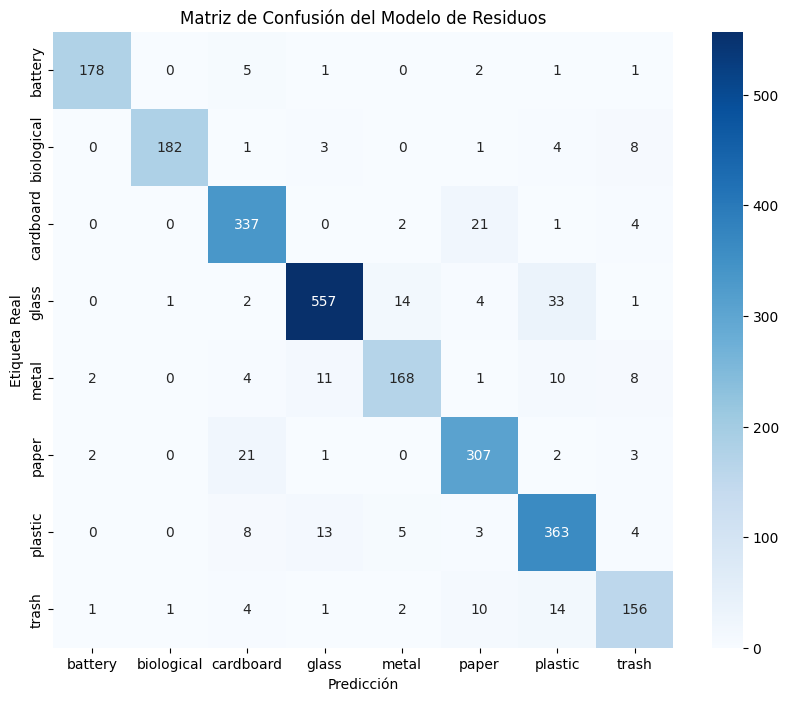

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Obtener predicciones
y_pred_probs = best_model.predict(val_generator)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = val_generator.classes

# Matriz de confusión
cm = confusion_matrix(y_true, y_pred)
class_names = list(val_generator.class_indices.keys())

# Graficar matriz de confusión
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicción')
plt.ylabel('Etiqueta Real')
plt.title('Matriz de Confusión del Modelo de Residuos')
plt.show()
